# OilWell AI ? exploratory data analysis

Phase 2: descriptive analysis of the 23 acquired, byte-preserved 3W v2.0.0 files. No preprocessing pipeline, split, classifier or training is created here. The subset is purposive and size-biased; 582,220 autocorrelated observations are not independent samples. All inspected instances and their well groups are development-exposed, not an untouched final test set.

**Sensor/target boundary:** only the 27 exact upstream sensor names enter sensor summaries and correlations. `class` is an observation label, `state` is an auxiliary status label, and source path/origin/well identifiers are metadata. Labels are used to describe EDA groups, never included as sensor inputs. Correlation does not establish physical causality.

Run using the project `.venv` after installing `requirements-eda.txt`. This notebook rebuilds reports from locally acquired originals; it does not download telemetry.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / "data/manifests/subset.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/manifests/subset.json").exists(), "Run from repository root or notebooks/"
sys.path.insert(0, str(ROOT))
from scripts.data.eda import build_eda
from IPython.display import display, Image
import pandas as pd
summary = build_eda(ROOT)
print({"python": sys.executable, "files": summary["total_files"], "rows": summary["total_rows"], "raw_unchanged": summary["raw_hashes_verified_before_and_after"]})


{'python': 'C:\\Home\\oilwell-ai\\.venv\\Scripts\\python.exe', 'files': 23, 'rows': 582220, 'raw_unchanged': True}


## Provenance and sampling limitations

The acquisition manifest pins commit `914af287b1cf3e5207dce0da1e9dc08361c9adeb`, exact filenames, original hashes and selection. One smallest file per available directory/origin stratum plus four new real well IDs covers 19 strata, but does not estimate corpus prevalence. Dataset Parquet license: CC BY 4.0; attribution: Petrobras and the 3W contributors. Every raw file's SHA-256 is verified before and after this EDA.

The original timezone-naive timestamps and missing values remain unchanged. A plot may scale Pa to MPa or select at most 1,500 points within each contiguous finite segment for readability. Full-resolution observations determine every statistic and label boundary; missing/timestamp gaps are not connected.

In [2]:
display(pd.DataFrame(summary["source_totals"]).T)
print("Real published well IDs exposed:", summary["eda_exposure"]["real_well_ids"])
print("Manifest SHA-256:", summary["provenance"]["input_manifest_sha256"])


,files,rows
real,14,322725
simulated,7,201894
drawn,2,57601


Real published well IDs exposed: ['WELL-00001', 'WELL-00002', 'WELL-00004', 'WELL-00005', 'WELL-00006', 'WELL-00008', 'WELL-00010', 'WELL-00011', 'WELL-00016', 'WELL-00024', 'WELL-00029', 'WELL-00036']
Manifest SHA-256: d5c4a0509fa242cc191578c77c3fe099163437da0a2a875ff2bcb851b55b1009


## Class imbalance: rows versus independent support

The left chart maps only documented transient codes to their event family for descriptive aggregation; raw codes remain available in `class_balance.csv`. Unknown labels stay separate. The right chart counts published real well IDs with actual row-label support, not directory membership. Thousands of rows from one well do not provide independent train/validation/test groups.

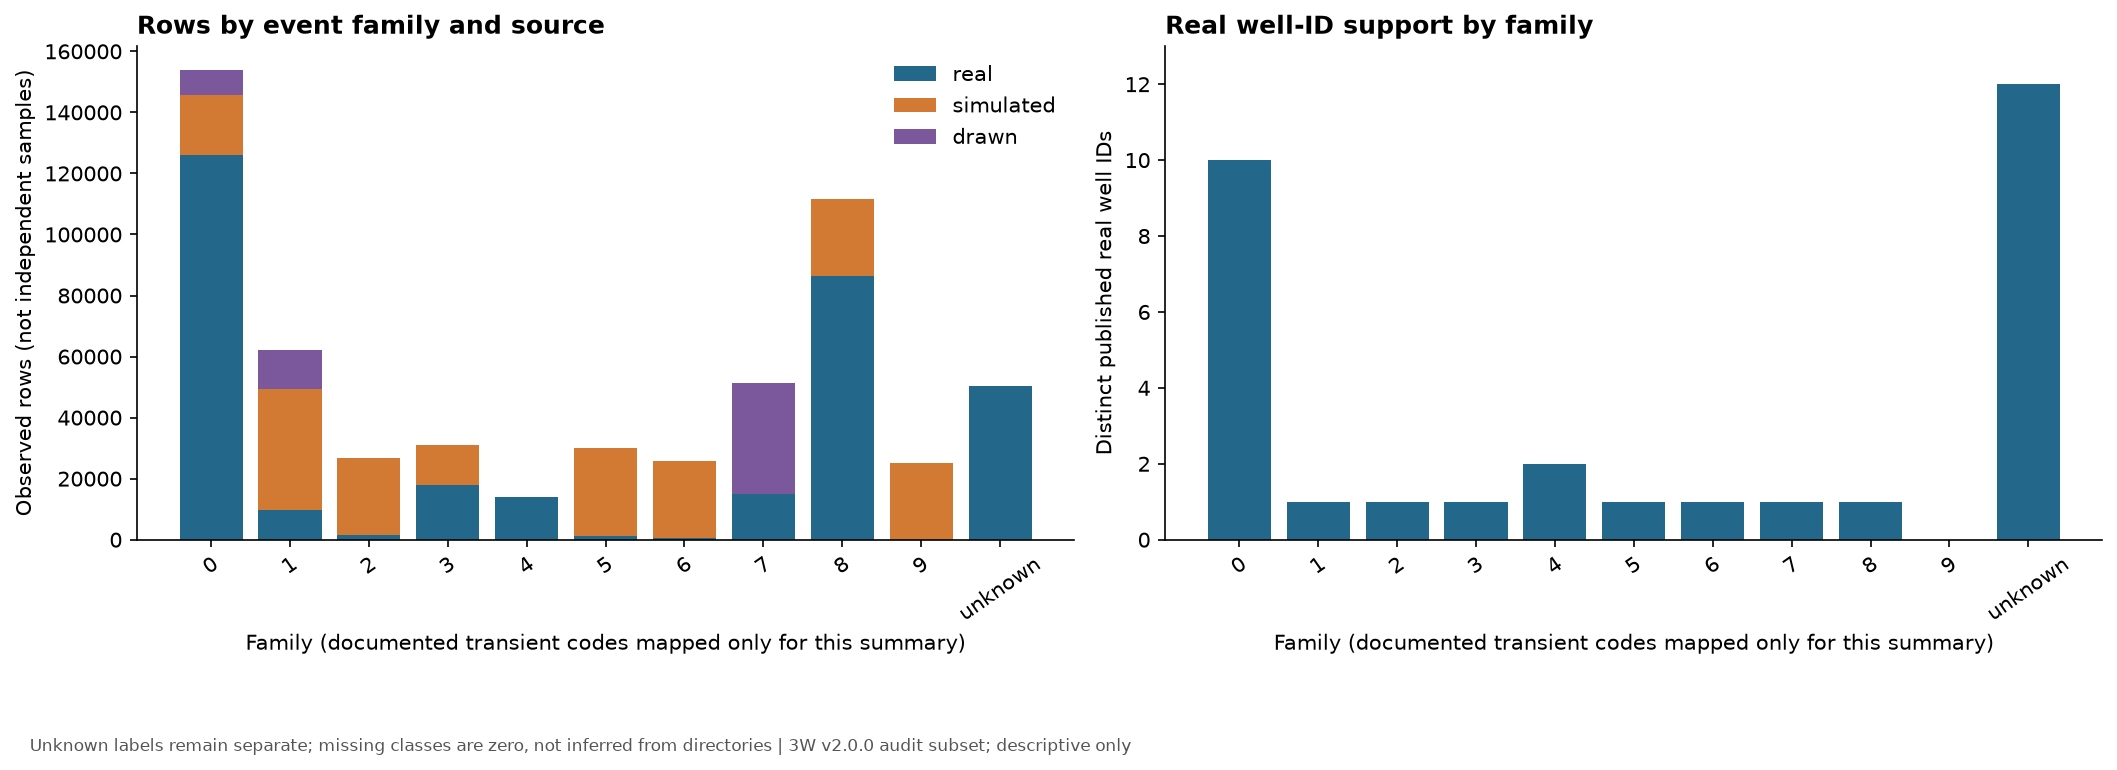

,normal,event,transient,unknown
real,125940,39291,107094,50400
simulated,19700,139035,43159,0
drawn,8331,1430,47840,0


In [3]:
display(Image(filename=str(ROOT / "reports/eda/01_class_balance.png")))
display(pd.DataFrame(summary["phase_rows_by_source"]).T.fillna(0).astype(int))


## Sensor availability and missingness

Read denominators and instance/well support in `missing_by_source_class.csv`; the first chart aggregates sensor null fractions by source, while the second uses real row-event families. Gray means no observations for that family, not zero missingness. Source-specific and well-specific availability may create shortcut learning. Missing label values are not sensor missingness and are not recoded as normal.

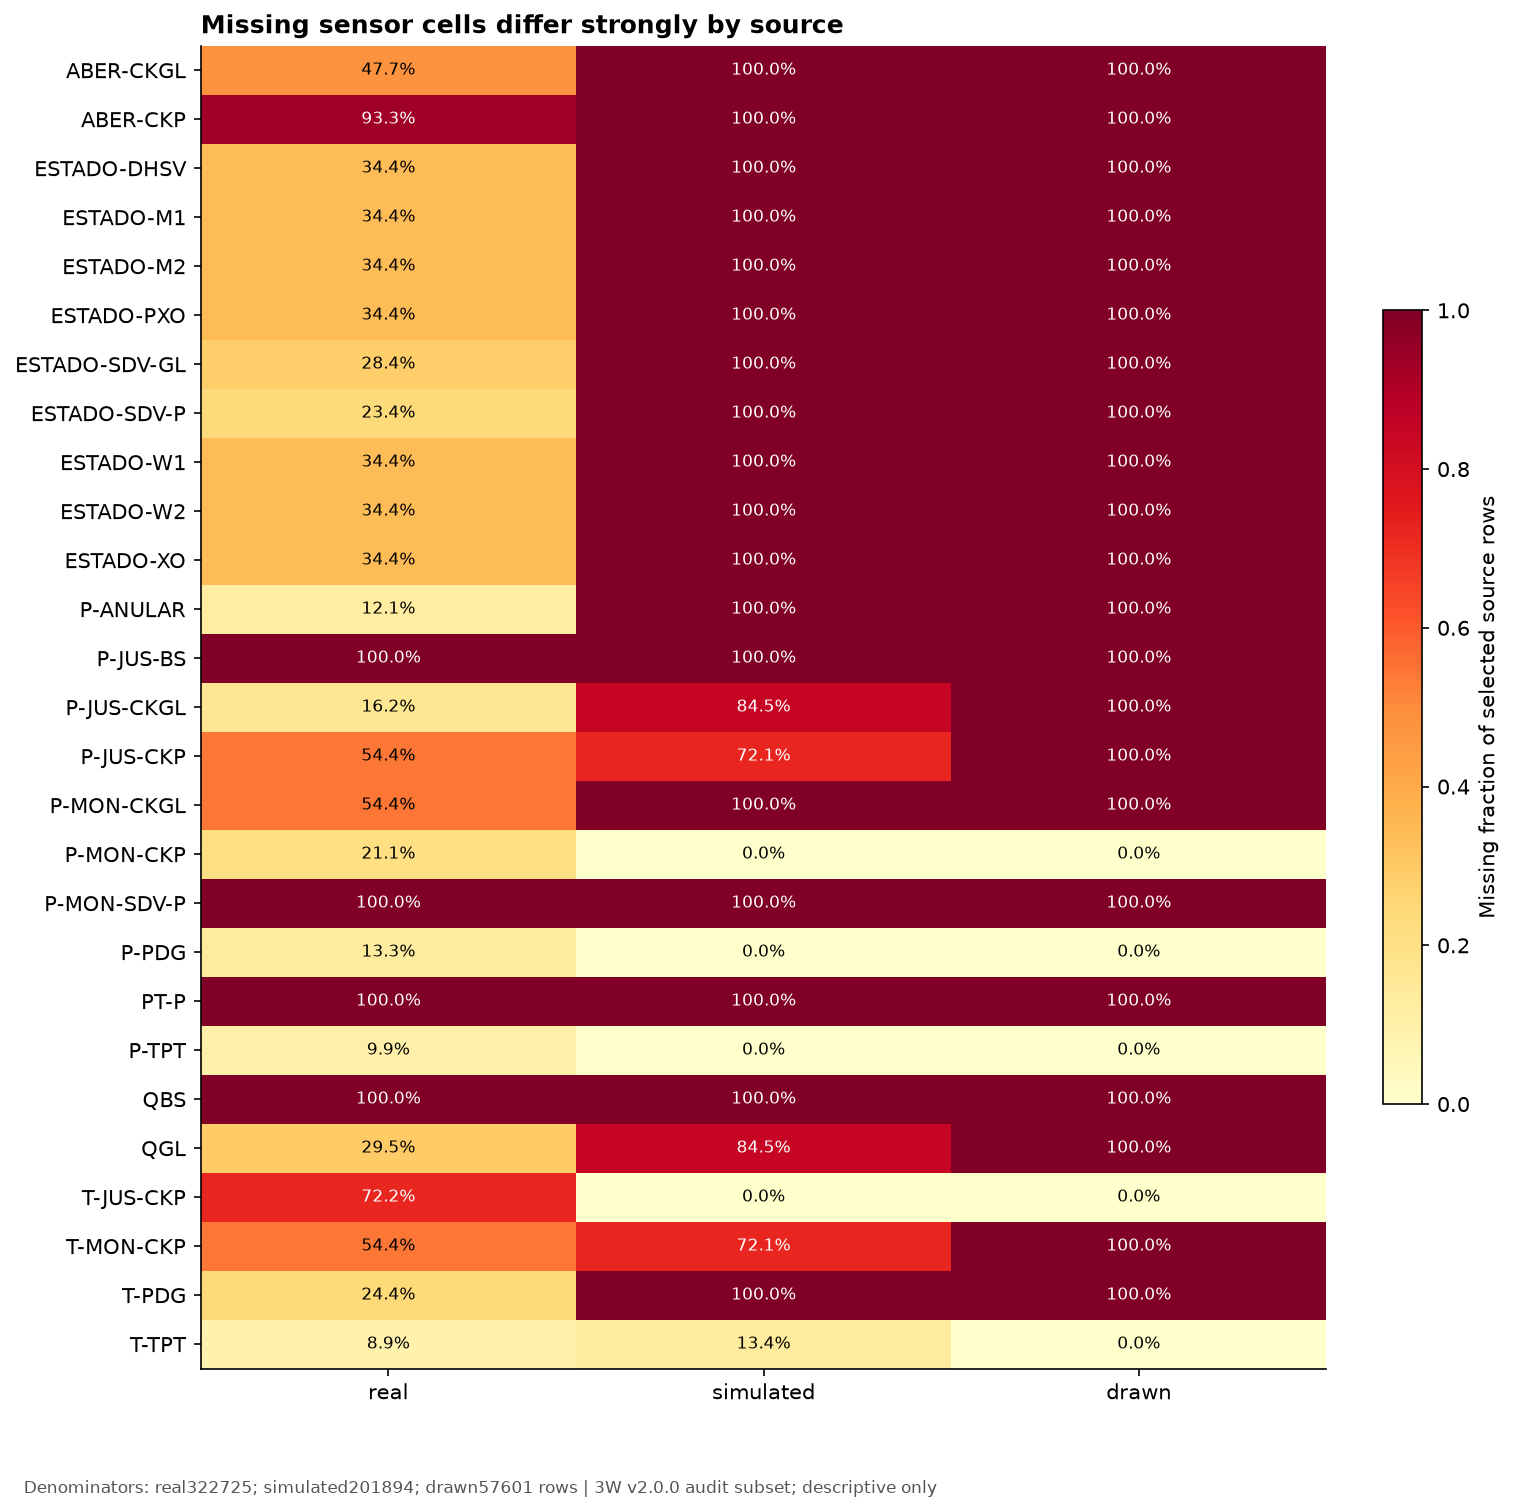

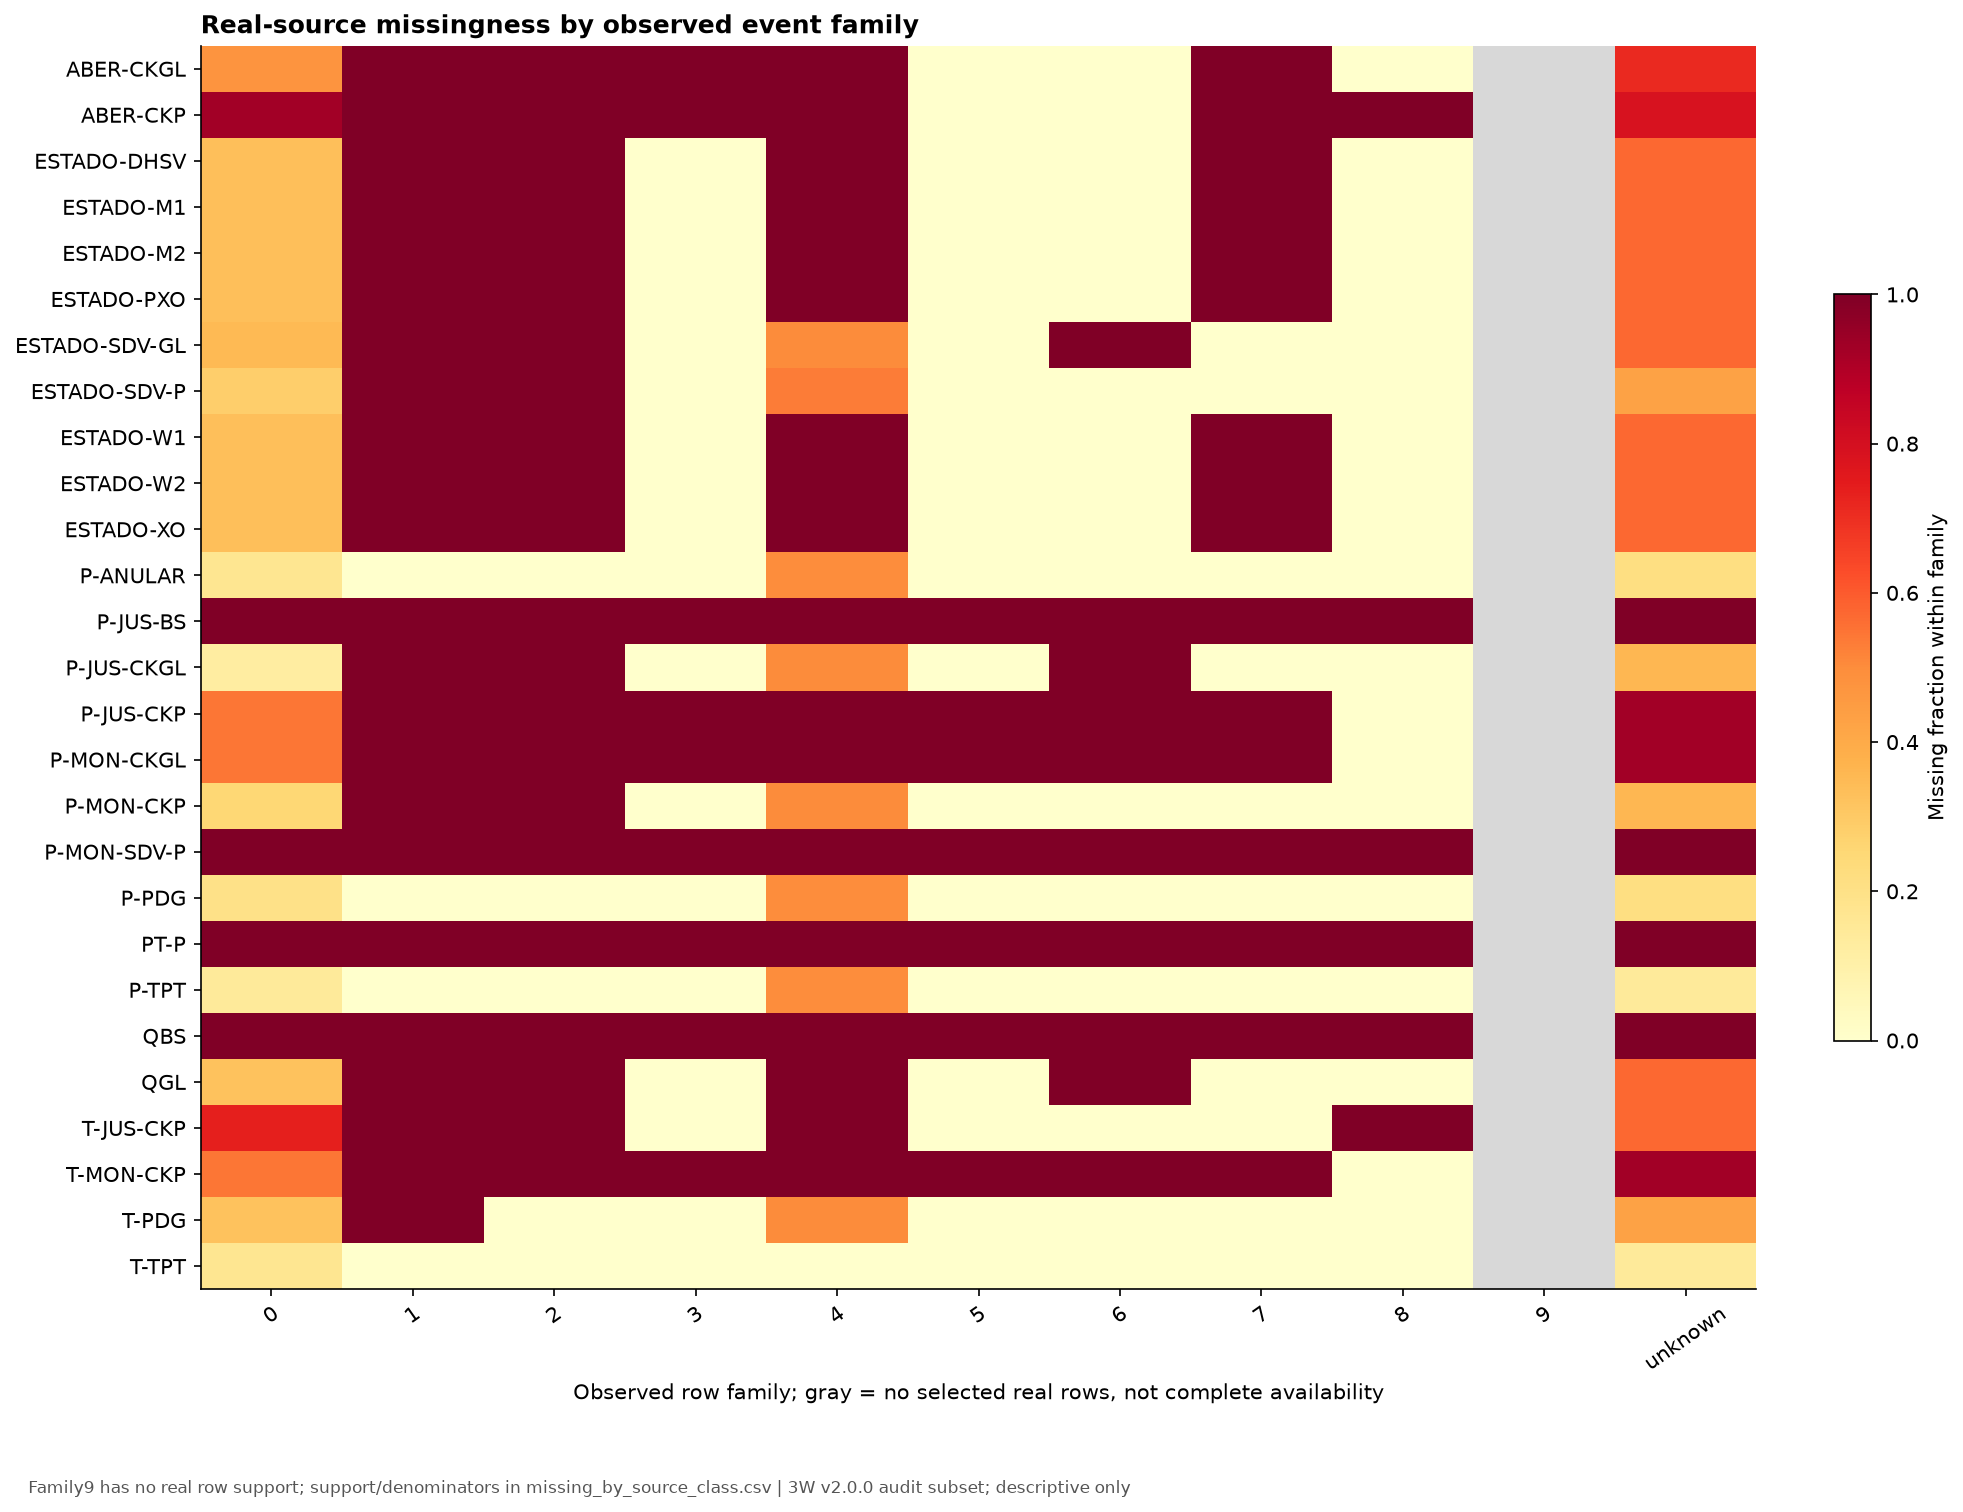

In [4]:
display(Image(filename=str(ROOT / "reports/eda/02_missing_by_source.png")))
display(Image(filename=str(ROOT / "reports/eda/03_missing_by_real_family.png")))


## Correlations are within-instance descriptions

Compute pairwise-complete Pearson correlations separately within each instance, requiring at least 120 paired observations. Undefined constant/empty pairs are omitted. The chart gives the equal-instance median within each origin, annotated with the number of instances contributing defined correlations. The diagonal is masked.

`correlations_within_instance.csv` retains every pair's observation count. `correlation_summary.csv` includes the full minimum/maximum range; its `pair_count_total` includes pairs from instances whose correlation is undefined, so it is **not** the denominator of the median. No inferential p-values, causal claims or model feature-selection conclusions are drawn. Two-instance medians can hide opposing signs.

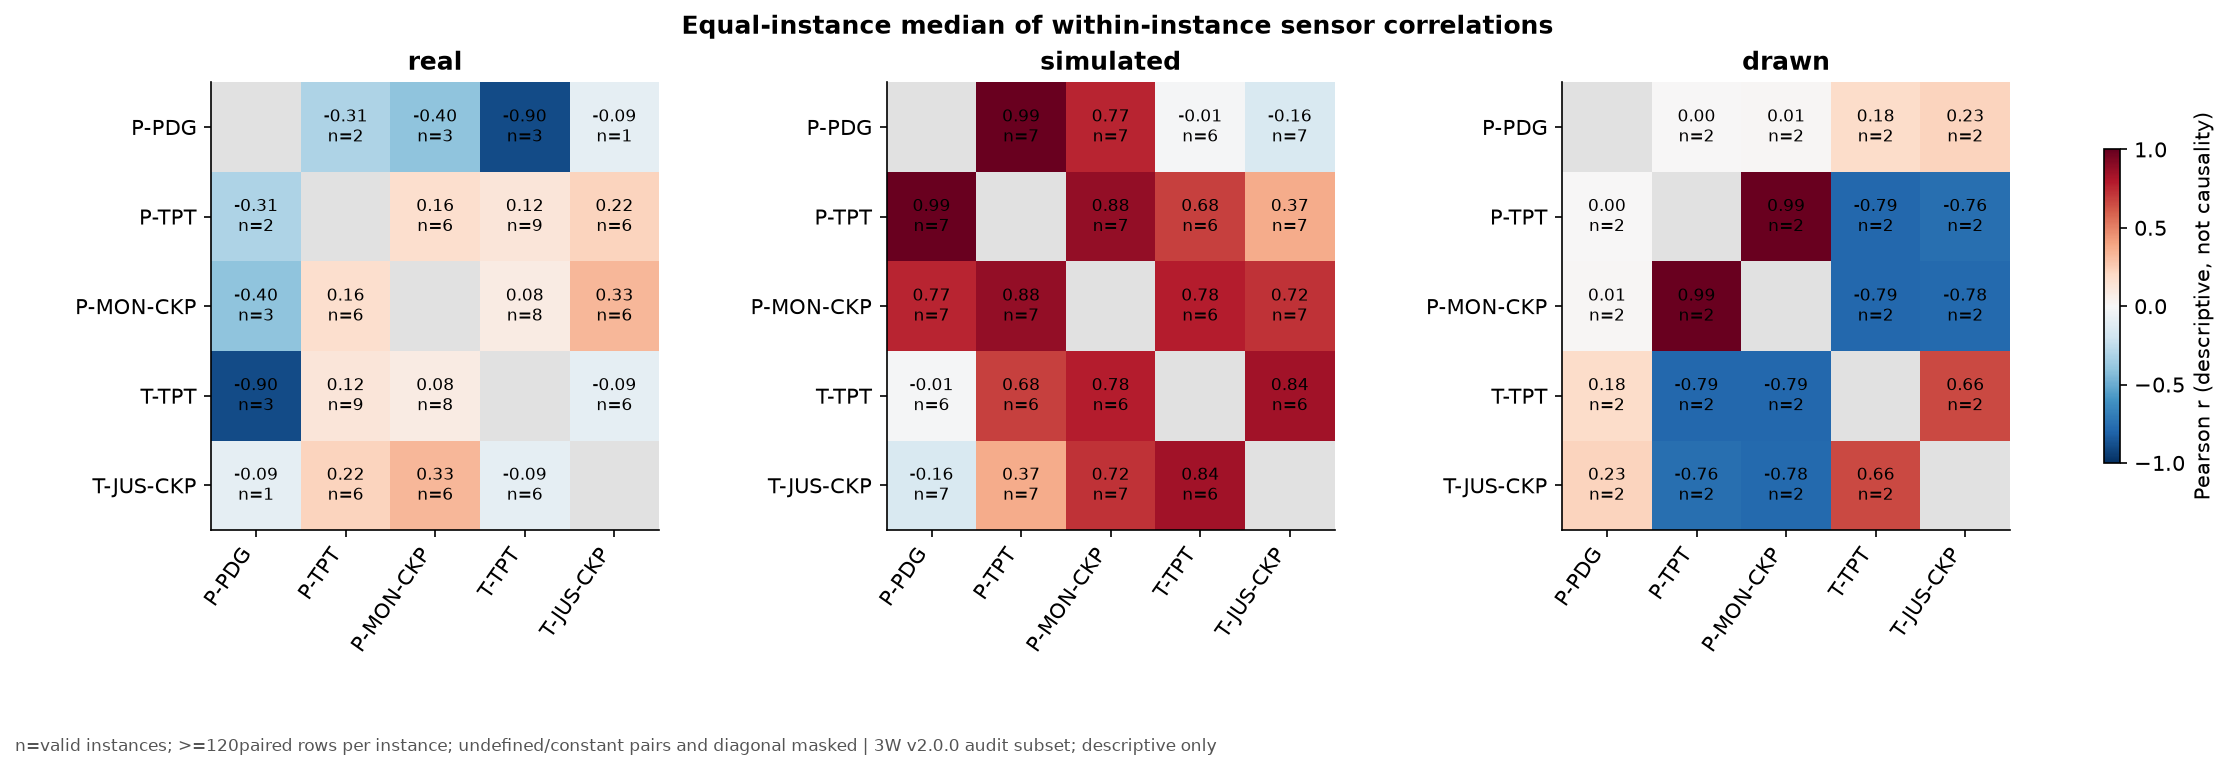

,source_kind,sensor_a,sensor_b,instance_count,valid_instance_count,pair_count_total,median_within_instance_pearson,minimum_within_instance_pearson,maximum_within_instance_pearson
315,drawn,P-PDG,P-TPT,2,2,57601,0.003558,-0.985493,0.992609
666,real,P-PDG,P-TPT,14,2,279894,-0.310667,-0.881231,0.259898
1017,simulated,P-PDG,P-TPT,7,7,201894,0.986770,-0.970710,0.999992


In [5]:
display(Image(filename=str(ROOT / "reports/eda/04_sensor_correlations.png")))
corr = pd.read_csv(ROOT / "reports/eda/correlation_summary.csv")
display(corr[(corr.sensor_a == "P-PDG") & (corr.sensor_b == "P-TPT")])


## Actual normal and abnormal examples

The next chart compares separate dates from the same published `WELL-00002` identity. It is not a matched physical experiment. Gray denotes unknown labels, green normal, amber documented transients and red event labels. File names and elapsed source time preserve provenance.

Some present sensors are constant, including zero-valued series. Availability is not informativeness; zero must not be relabeled as missing without upstream evidence. The per-instance normal/abnormal comparison uses medians and does not imply a sensor caused an event.

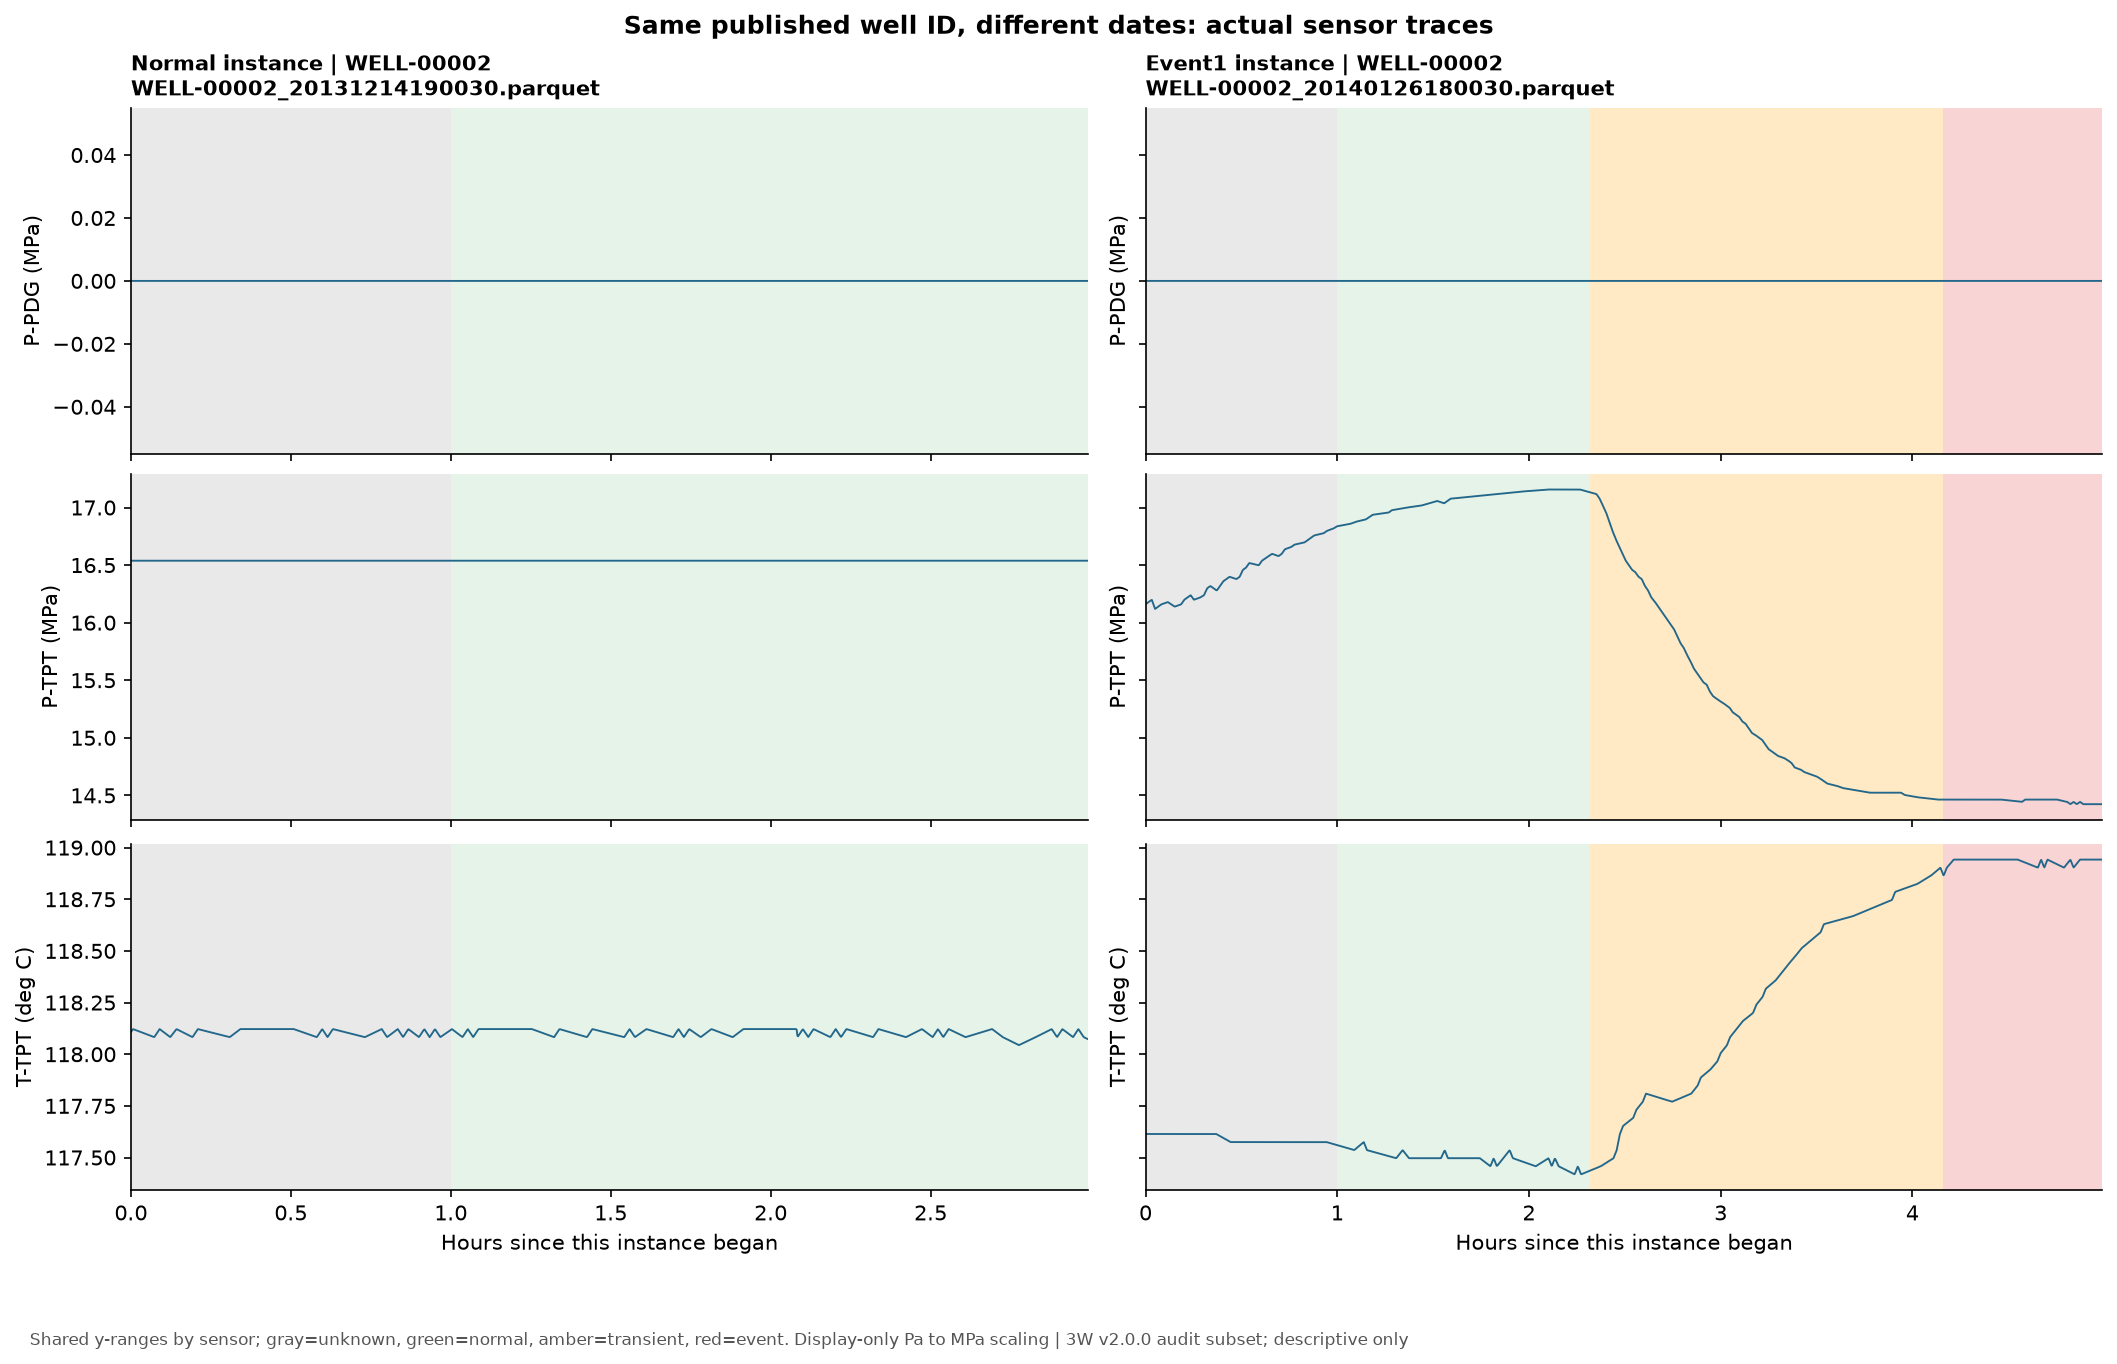

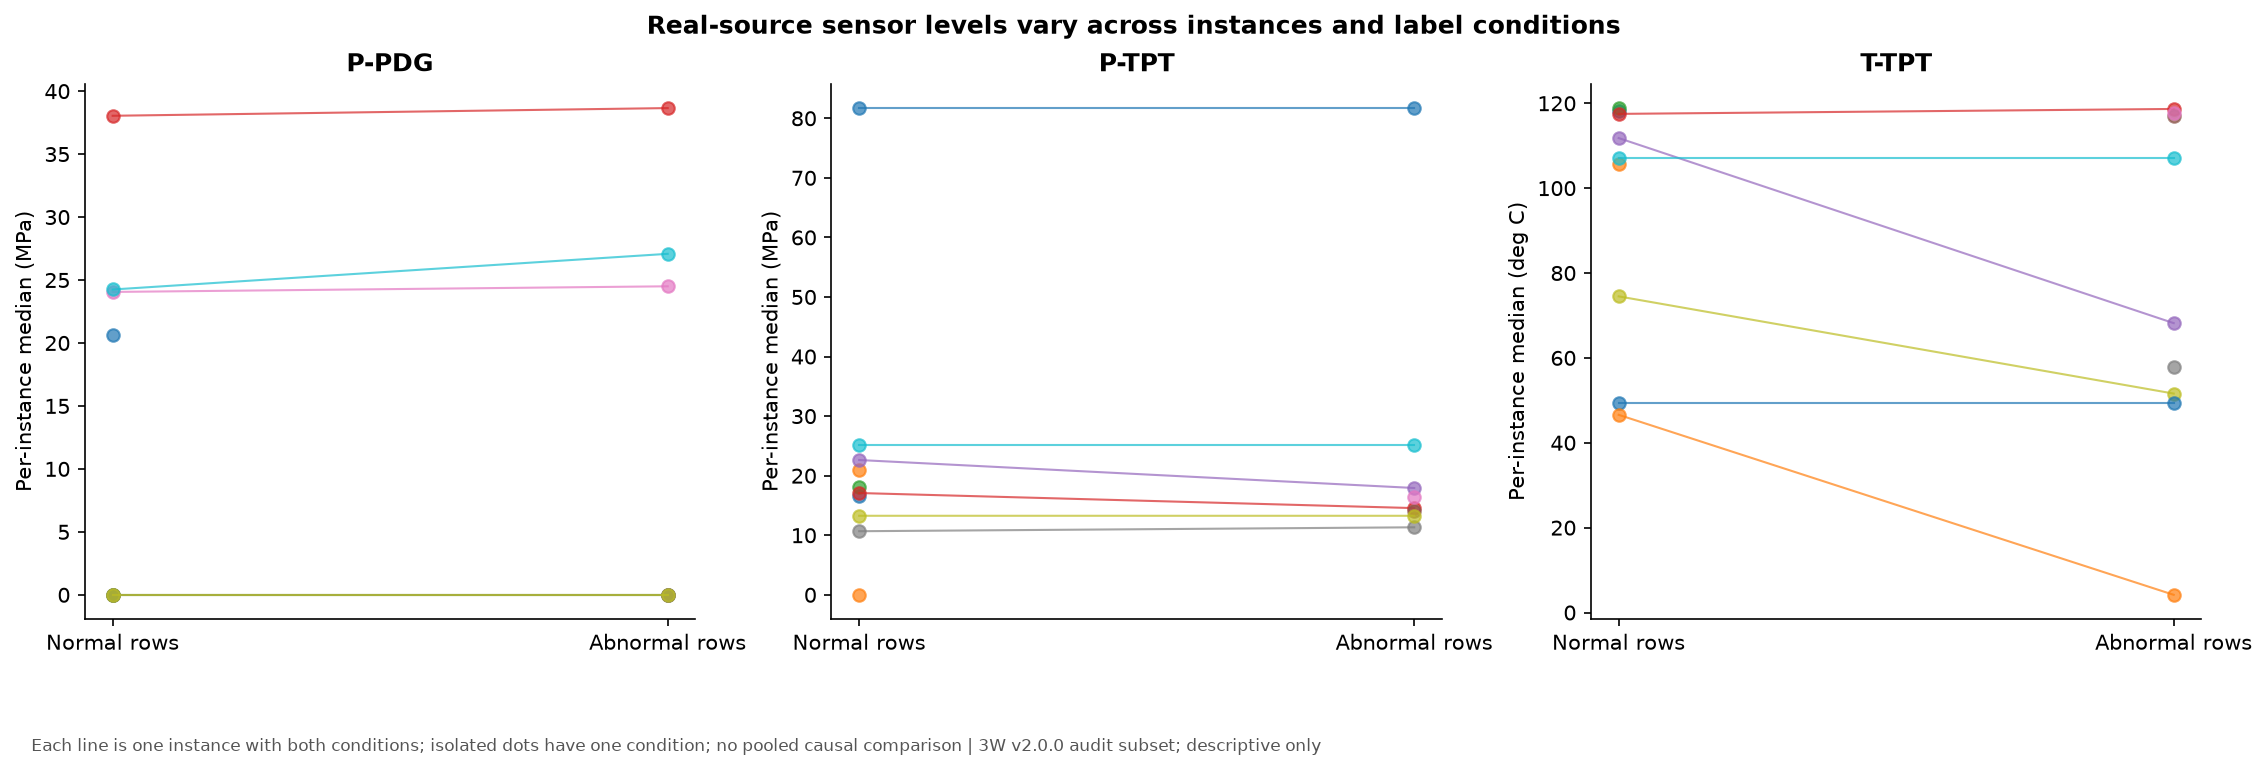

In [6]:
display(Image(filename=str(ROOT / "reports/eda/05_real_normal_vs_event.png")))
display(Image(filename=str(ROOT / "reports/eda/08_normal_abnormal.png")))


## Real, simulated and hand-drawn sources

The three event-1 instances below have different durations, sensor behavior and label schedules. These are selected examples, not interchangeable experiments. Synthetic sources have structural channel differences and should not substitute for independent real holdout groups. Compare source-conditioned distributions before considering synthetic training augmentation in a later approved phase.

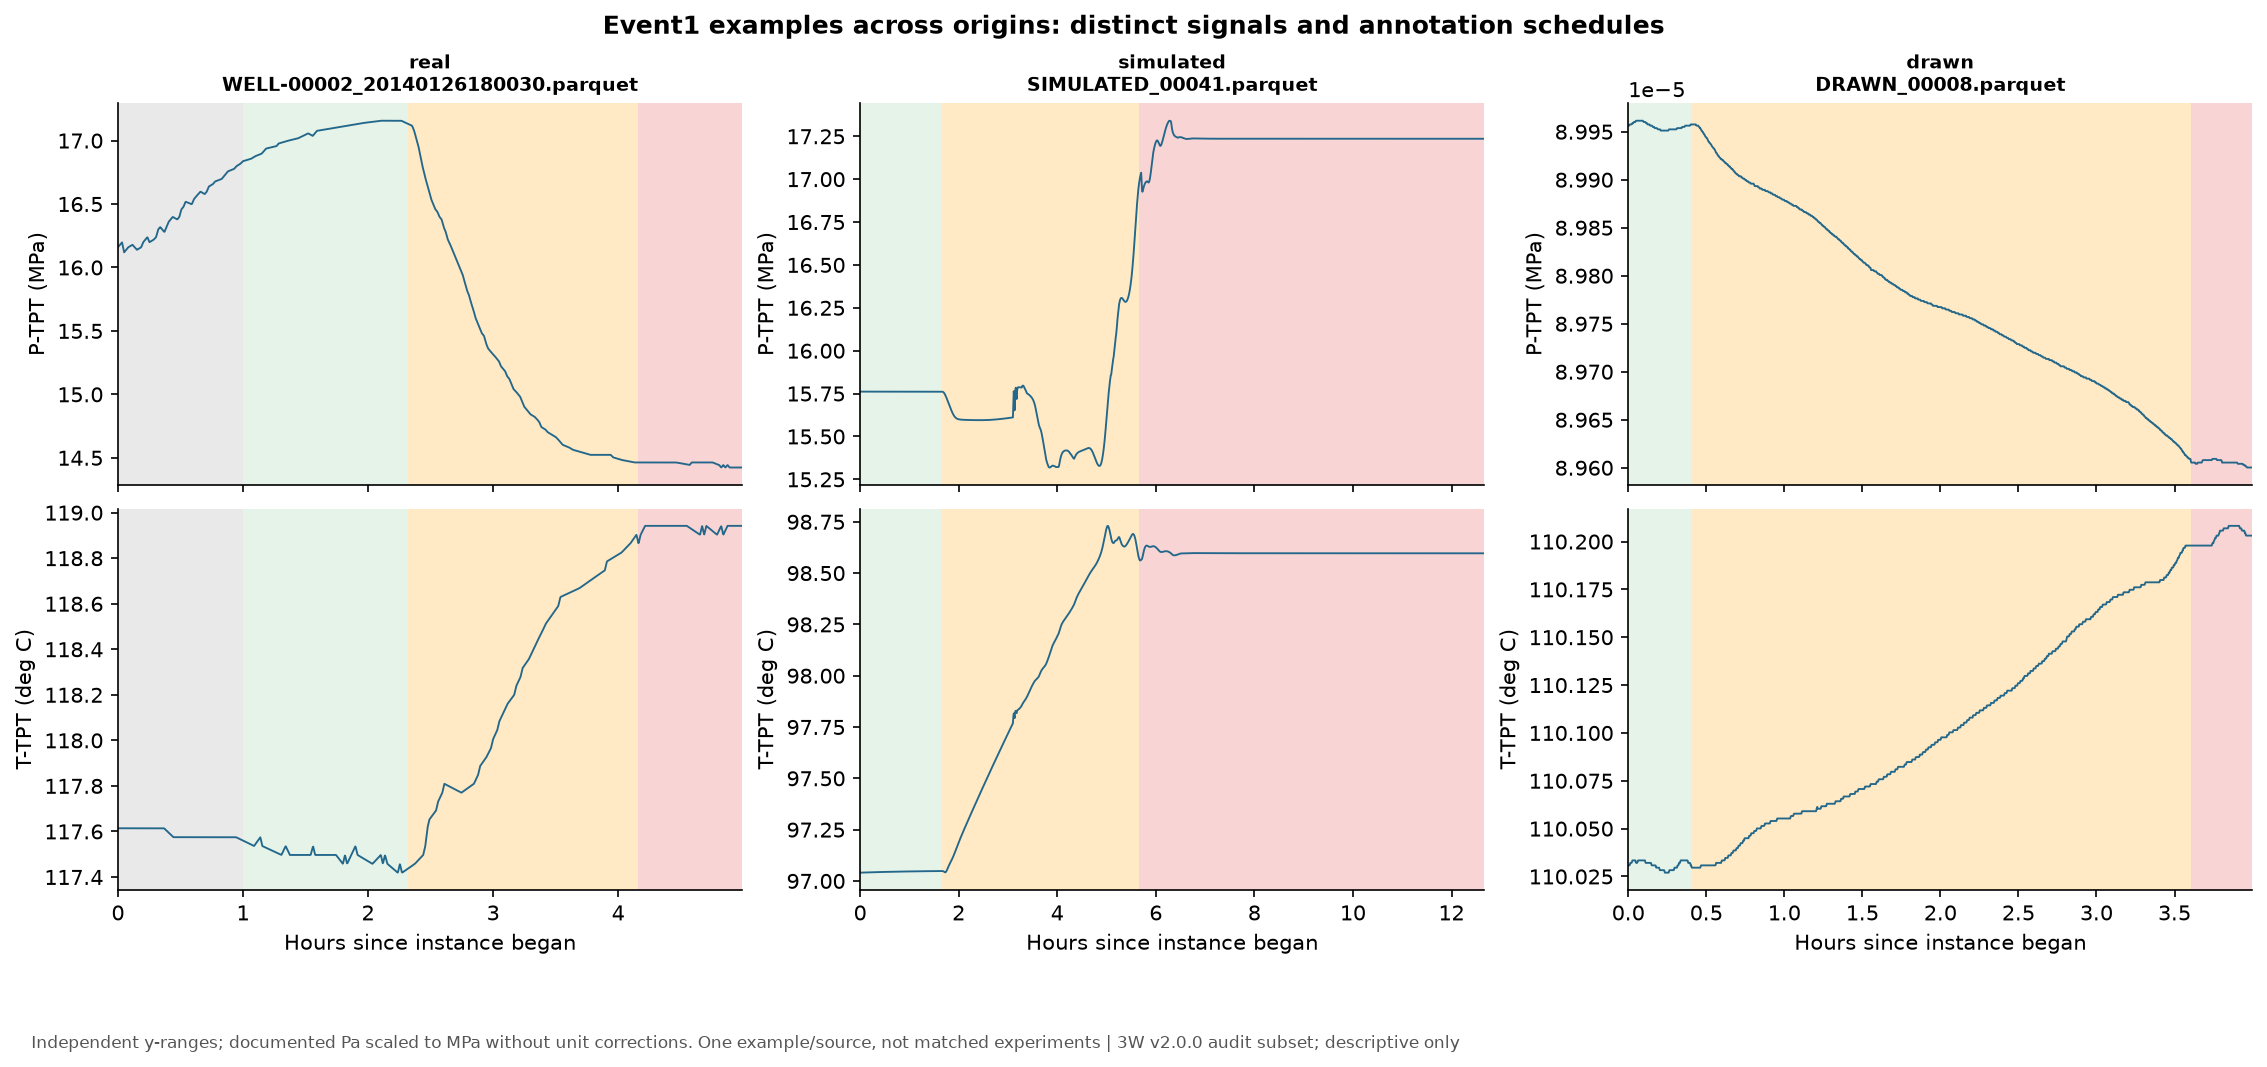

In [7]:
display(Image(filename=str(ROOT / "reports/eda/06_source_timeseries.png")))


## Event transitions and censoring

Transitions are counted only between adjacent one-second rows in the same source file. A null label or a timestamp gap breaks a known-label run. Unknown-to-known boundaries are diagnostics, not confirmed physical event onsets. Runs touching a file boundary, a null label or a gap are left/right-censored.

Duration is observed one-second support: a single observation contributes one second, while last-minus-first elapsed time would be zero. These run lengths are not verified full physical event durations. The outline on a transient point denotes censoring.

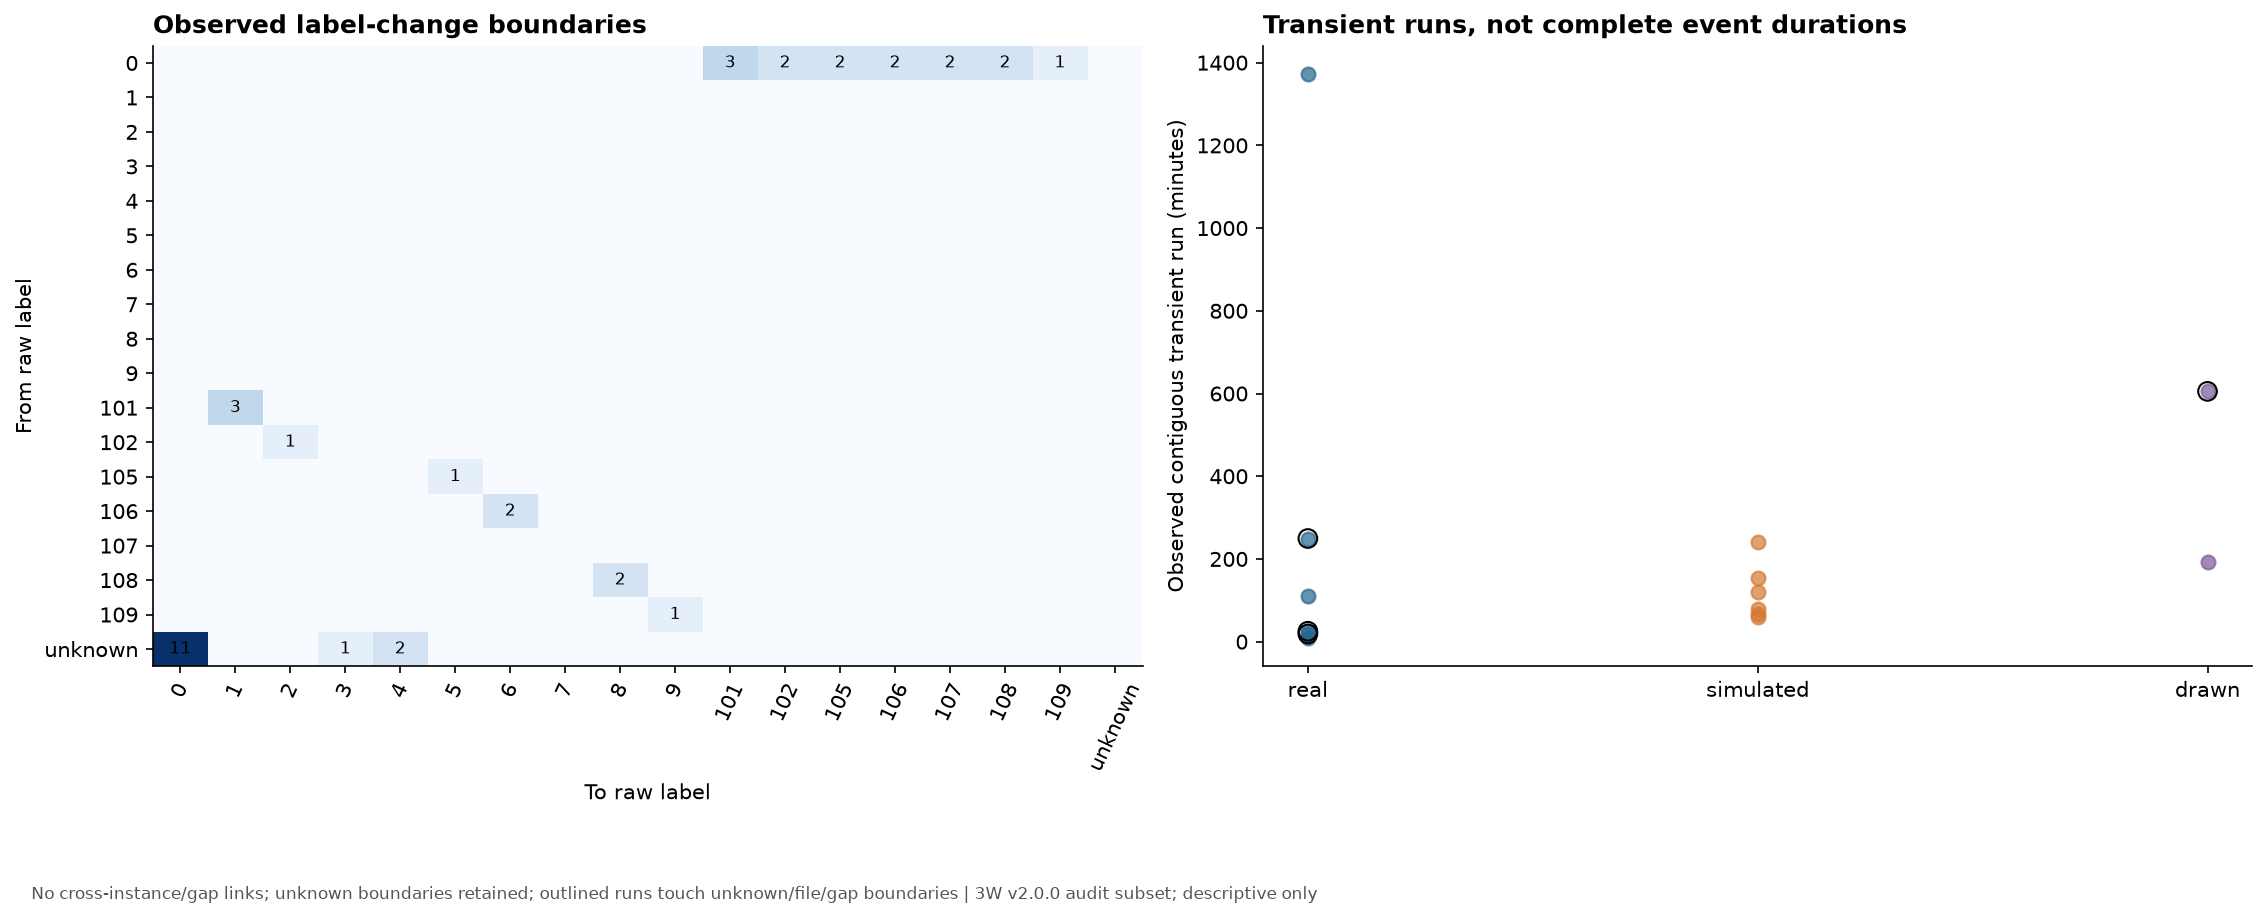

{'total': 61, 'known_label_transition_count': 24, 'unknown_boundary_transition_count': 14, 'transient_runs': 14, 'censored_transient_runs': 4}


,source_kind,known_labels,boundaries
0,drawn,True,3
1,real,False,14
2,real,True,9
3,simulated,True,12


In [8]:
display(Image(filename=str(ROOT / "reports/eda/07_label_transitions.png")))
print(summary["runs"])
display(pd.read_csv(ROOT / "reports/eda/transitions.csv").groupby(["source_kind", "known_labels"]).size().rename("boundaries").reset_index())


## Modeling implications and next gate

Current data supports descriptive exploration only. Several real event families occur in one published well group, the selected real rows have no family 9, and a single family-8 instance dominates real abnormal row counts. No clean final test set remains inside these EDA-exposed sources.

Keep all related source instances from the same published well ID together before windows; investigate duplicates/overlaps and uncertain synthetic families. For a future evaluation, obtain a separately approved group-disjoint real cohort and lock an untouched test manifest before model-driven choices. Instance-level fallback cannot support an unseen-well claim.

See `docs/ML_HYPOTHESES.md` for falsifiable experiments and `docs/SPLIT_STRATEGY.md` for the recommended split gates. Neither is evidence of executed model experiments. Phase 2 stops here, without training.